In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pathlib as path #provides classes that represent filesystem paths as objects

In [5]:
gain = 0.718
offset = 73.638

root_dir = path.Path('homerton_data')

data_method_dir = root_dir / 'web_data' # change this to root_dir / 'API_data' if using api folder data
time_col = 'UTC Date/Time'  #change this to 'timestamp' if using api folder data
co2_col = 'CO2 (ppm) raw'  #change this to 'rco2_corrected' if using api folder data
valid_cols = ['UTC Date/Time','CO2 (ppm) raw','Temperature (°C) raw','Humidity (%) raw','ground', 'temp', 'rh', 'lat', 'lon', 'notes', 'reading_id'] 
#API Column Headings: ['atmp','timestamp','rco2_corrected','ground', 'temp', 'rh', 'lat', 'lon', 'notes'] 
#web column headings: ['UTC Date/Time','CO2 (ppm) raw','Temperature (°C) raw','Humidity (%) raw','ground', 'temp', 'rh', 'lat', 'lon', 'notes']


meta_file = root_dir / 'meta_hom.csv'

meta = pd.read_csv(meta_file)



In [6]:
frames = []
raw_cache = {}  # read each day's file once, not once per metadata row




for i, r in meta.iterrows():
    # Load and parse the day's raw file (cached)
    if r['day'] not in raw_cache:
        df = pd.read_csv(data_method_dir / f"{r['day']}.csv") 
        df[time_col] = pd.to_datetime(df[time_col])
        raw_cache[r['day']] = df
    raw = raw_cache[r['day']]

    # Combine the date with the clock times
    date = pd.to_datetime(r['date'], dayfirst=True).strftime('%Y-%m-%d')
    start_time = pd.to_datetime(f"{date} {r['start']}").tz_localize('Europe/London').tz_convert('UTC')
    end_time   = (pd.to_datetime(f"{date} {r['end']}").tz_localize('Europe/London').tz_convert('UTC') + pd.Timedelta(minutes=1))

    mask = (raw[time_col] >= start_time) & (raw[time_col] < end_time)
    data = raw.loc[mask].copy()
    data['reading_id'] = i

    for col in ['ground', 'temp', 'rh', 'lat', 'lon', 'notes']:
        data[col] = r[col]

    frames.append(data)

data = pd.concat(frames, ignore_index=True)


In [7]:
data


,Location ID,Location Name,Location Group,Location Type,Sensor ID,Local Date/Time,UTC Date/Time,Channel,PM2.5 (μg/m³) raw,0.3um particle count,...,measure17,measure18,measure19,reading_id,ground,temp,rh,lat,lon,notes
0,173038,d83bda1ac7e0_A10,NaN,Outdoor,airgradient:d83bda1ac7e0,2026-11-18 08:44:30,2026-11-18 08:44:30+00:00,-,0.00,68.33,...,NaN,NaN,NaN,0,concrete,11.1,57.0,52.18509,0.13425,NaN
1,173038,d83bda1ac7e0_A10,NaN,Outdoor,airgradient:d83bda1ac7e0,2026-11-18 08:43:30,2026-11-18 08:43:30+00:00,-,0.00,74.00,...,NaN,NaN,NaN,0,concrete,11.1,57.0,52.18509,0.13425,NaN
2,173038,d83bda1ac7e0_A10,NaN,Outdoor,airgradient:d83bda1ac7e0,2026-11-18 08:42:30,2026-11-18 08:42:30+00:00,-,0.00,69.33,...,NaN,NaN,NaN,0,concrete,11.1,57.0,52.18509,0.13425,NaN
3,173038,d83bda1ac7e0_A10,NaN,Outdoor,airgradient:d83bda1ac7e0,2026-11-18 08:41:30,2026-11-18 08:41:30+00:00,-,0.00,67.33,...,NaN,NaN,NaN,0,concrete,11.1,57.0,52.18509,0.13425,NaN
4,173038,d83bda1ac7e0_A10,NaN,Outdoor,airgradient:d83bda1ac7e0,2026-11-18 08:40:30,2026-11-18 08:40:30+00:00,-,0.00,59.33,...,NaN,NaN,NaN,0,concrete,11.1,57.0,52.18509,0.13425,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
897,173038,d83bda1ac7e0_A10,NaN,Outdoor,airgradient:d83bda1ac7e0,20/11/2026 19:55,2026-11-20 19:55:32+00:00,-,6.17,363.17,...,NaN,NaN,NaN,80,concrete,4.4,79.0,52.18510,0.13412,NaN
898,173038,d83bda1ac7e0_A10,NaN,Outdoor,airgradient:d83bda1ac7e0,20/11/2026 19:54,2026-11-20 19:54:32+00:00,-,7.00,355.50,...,NaN,NaN,NaN,80,concrete,4.4,79.0,52.18510,0.13412,NaN
899,173038,d83bda1ac7e0_A10,NaN,Outdoor,airgradient:d83bda1ac7e0,20/11/2026 19:53,2026-11-20 19:53:32+00:00,-,7.00,376.33,...,NaN,NaN,NaN,80,concrete,4.4,79.0,52.18510,0.13412,NaN
900,173038,d83bda1ac7e0_A10,NaN,Outdoor,airgradient:d83bda1ac7e0,20/11/2026 19:52,2026-11-20 19:52:32+00:00,-,7.67,366.83,...,NaN,NaN,NaN,80,concrete,4.4,79.0,52.18510,0.13412,NaN


In [ ]:
scrubbed_data = data.loc[:, valid_cols] 


In [ ]:
print(np.max(scrubbed_data['reading_id']))

80


In [10]:
time_of_day = []
for i, r in scrubbed_data.iterrows():
    time = r[time_col]
    if time.hour < 12:
        time_of_day.append('morning')
    elif time.hour >=12 and time.hour < 17:
        time_of_day.append('afternoon')
    else:
        time_of_day.append('evening')

scrubbed_data['tod'] = time_of_day

scrubbed_data


,UTC Date/Time,CO2 (ppm) raw,Temperature (°C) raw,Humidity (%) raw,ground,temp,rh,lat,lon,notes,reading_id,tod
0,2026-11-18 08:44:30+00:00,366.67,21.40,37.67,concrete,11.1,57.0,52.18509,0.13425,NaN,0,morning
1,2026-11-18 08:43:30+00:00,367.33,21.68,37.32,concrete,11.1,57.0,52.18509,0.13425,NaN,0,morning
2,2026-11-18 08:42:30+00:00,368.00,22.00,36.80,concrete,11.1,57.0,52.18509,0.13425,NaN,0,morning
3,2026-11-18 08:41:30+00:00,368.00,22.33,36.25,concrete,11.1,57.0,52.18509,0.13425,NaN,0,morning
4,2026-11-18 08:40:30+00:00,368.00,22.60,35.83,concrete,11.1,57.0,52.18509,0.13425,NaN,0,morning
...,...,...,...,...,...,...,...,...,...,...,...,...
897,2026-11-20 19:55:32+00:00,428.00,9.00,53.02,concrete,4.4,79.0,52.18510,0.13412,NaN,80,evening
898,2026-11-20 19:54:32+00:00,429.00,9.07,52.78,concrete,4.4,79.0,52.18510,0.13412,NaN,80,evening
899,2026-11-20 19:53:32+00:00,429.00,9.10,52.50,concrete,4.4,79.0,52.18510,0.13412,NaN,80,evening
900,2026-11-20 19:52:32+00:00,428.00,9.17,52.32,concrete,4.4,79.0,52.18510,0.13412,NaN,80,evening


In [7]:
import plotly.express as px

px.scatter_map(scrubbed_data, lat='lat', lon='lon', color='ground', map_style='satellite')

In [ ]:
sus_lat = [52.18488, 52.18428, 52.18511]


sus_lats = [
    scrubbed_data.loc[np.isclose(scrubbed_data['lat'], lat), time_col].iloc[0]
    for lat in sus_lat
]

sus_lats = [f'{sus.day_name()}, {sus.strftime("%H:%M")}' for sus in sus_lats]
sus_lats


['Wednesday, 08:44', 'Wednesday, 09:33', 'Wednesday, 08:44']

In [11]:
cal = lambda x: (x - offset)/gain
scrubbed_data['co2_cal'] = cal(scrubbed_data[co2_col])


print(bool(cal(scrubbed_data[co2_col].iloc[0]) - scrubbed_data['co2_cal'].iloc[0] < 1e-6))
print(bool((scrubbed_data[co2_col].iloc[0] - offset)/gain - scrubbed_data['co2_cal'].iloc[0] < 1e-6))


True
True


(array([  2.,  19., 109., 161.,  88.,  62.,  51.,  36.,  30.,  60.,  38.,
         22.,  24.,  17.,   9.,  15.,  17.,  12.,  15.,   4.,  11.,   8.,
          8.,   5.,   8.,   6.,   6.,   1.,   5.,   2.,   5.,   2.,   7.,
          3.,   4.,   2.,   7.,   1.,   1.,   1.,   1.,   2.,   0.,   2.,
          2.,   3.,   3.,   3.,   1.,   1.]),
 array([ 364.01392758,  377.39359331,  390.77325905,  404.15292479,
         417.53259053,  430.91225627,  444.29192201,  457.67158774,
         471.05125348,  484.43091922,  497.81058496,  511.1902507 ,
         524.56991643,  537.94958217,  551.32924791,  564.70891365,
         578.08857939,  591.46824513,  604.84791086,  618.2275766 ,
         631.60724234,  644.98690808,  658.36657382,  671.74623955,
         685.12590529,  698.50557103,  711.88523677,  725.26490251,
         738.64456825,  752.02423398,  765.40389972,  778.78356546,
         792.1632312 ,  805.54289694,  818.92256267,  832.30222841,
         845.68189415,  859.06155989,  872.441

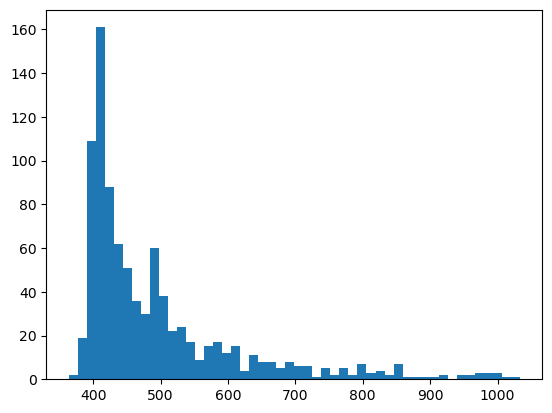

In [16]:
plt.hist(scrubbed_data['co2_cal'], bins=50)

['Wednesday, 19:42',
 'Wednesday, 19:41',
 'Wednesday, 19:40',
 'Wednesday, 19:56',
 'Wednesday, 19:55',
 'Wednesday, 19:54',
 'Wednesday, 19:53',
 'Thursday, 09:14',
 'Thursday, 09:13',
 'Thursday, 09:12',
 'Thursday, 09:11',
 'Thursday, 09:10',
 'Thursday, 09:09',
 'Thursday, 09:08',
 'Thursday, 09:07',
 'Thursday, 09:06',
 'Thursday, 09:29',
 'Thursday, 09:28',
 'Thursday, 09:42',
 'Thursday, 14:32',
 'Thursday, 14:31',
 'Thursday, 14:30',
 'Thursday, 14:29',
 'Thursday, 14:28',
 'Thursday, 14:27',
 'Thursday, 14:26',
 'Thursday, 14:25',
 'Thursday, 14:45',
 'Friday, 14:41',
 'Friday, 18:52',
 'Friday, 18:51',
 'Friday, 19:08',
 'Friday, 19:07',
 'Friday, 19:06',
 'Friday, 19:05',
 'Friday, 19:04',
 'Friday, 19:23',
 'Friday, 19:22',
 'Friday, 19:21',
 'Friday, 19:20',
 'Friday, 19:19']

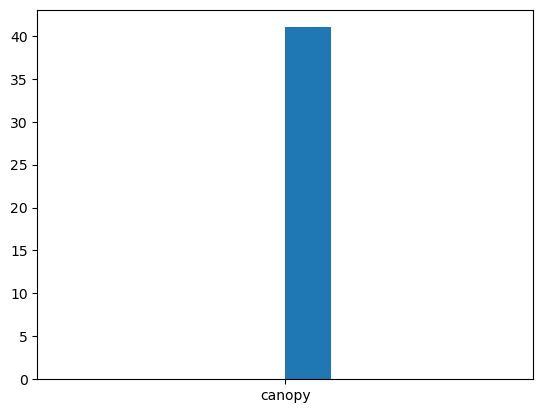

In [19]:
high = scrubbed_data.loc[scrubbed_data['co2_cal'] > 800]
plt.hist(high['ground'],bins = 10)
high_co2 = high[time_col].tolist()
high_co2 = [f'{hi.day_name()}, {hi.strftime("%H:%M")}' for hi in high_co2]
high_co2

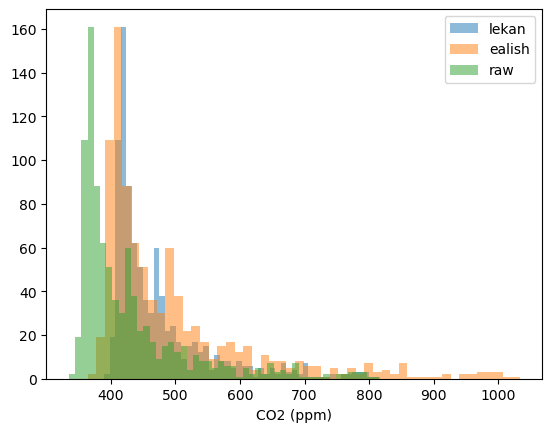

In [12]:
gain_lek = 0.887898345
offset_lek = 92.19975095
 
cal_lek = lambda x: x*gain_lek + offset_lek

scrubbed_data['co2_cal_lek'] = cal_lek(scrubbed_data[co2_col])

plt.hist(scrubbed_data['co2_cal_lek'], bins=50, alpha=0.5, label='lekan')
plt.hist(scrubbed_data['co2_cal'], bins=50, alpha=0.5, label='ealish')
plt.hist(scrubbed_data[co2_col], bins=50, alpha=0.5, label='raw')
plt.xlabel('CO2 (ppm)')
plt.legend()

Text(0.5, 0.98, 'lekan calibration')

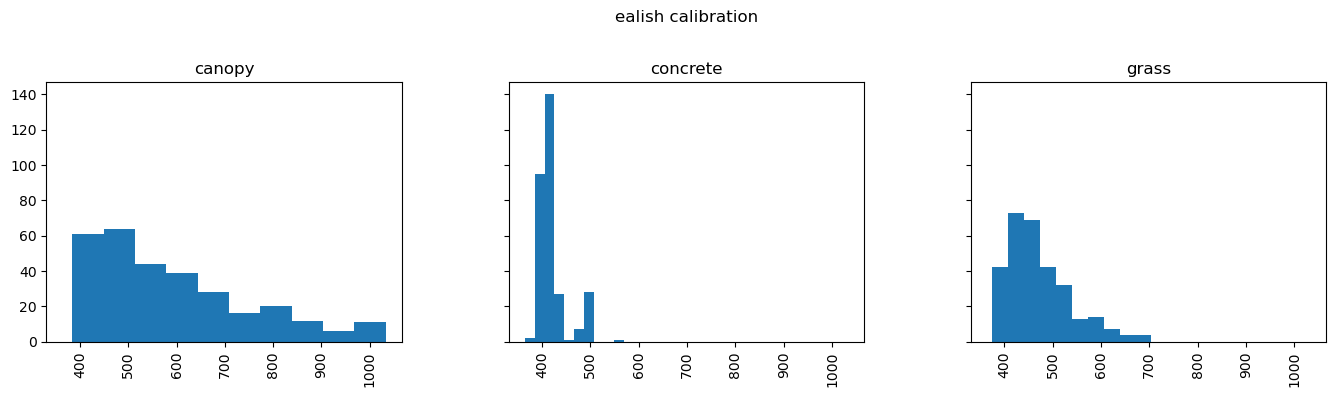

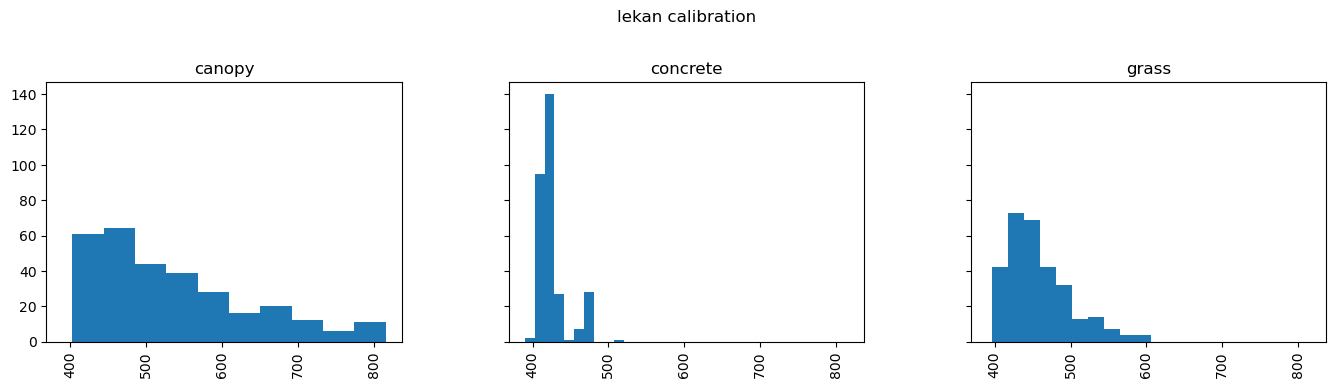

In [31]:
scrubbed_data.hist(column='co2_cal', by='ground',  sharex=True, sharey=True, layout=(1, 3), figsize=(16,4))
plt.subplots_adjust(top = 0.8)
plt.suptitle('ealish calibration')

scrubbed_data.hist(column='co2_cal_lek', by='ground',  sharex=True, sharey=True, layout=(1, 3), figsize=(16,4))
plt.subplots_adjust(top = 0.8)
plt.suptitle('lekan calibration')

In [13]:
scrubbed_data.to_parquet(data_method_dir / 'scrubbed_data.parquet')

Max Temperature Difference: 14.48°C


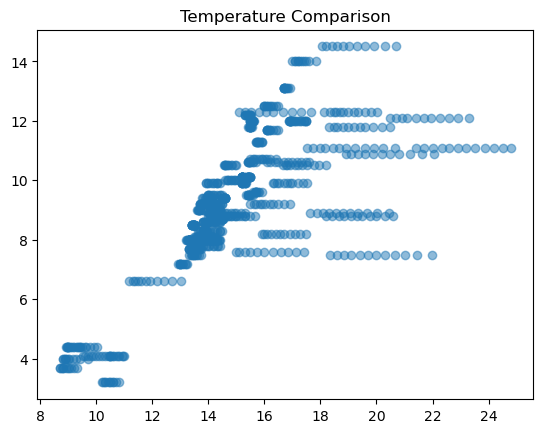

In [36]:
plt.scatter(scrubbed_data['Temperature (°C) raw'], scrubbed_data['temp'], alpha=0.5)
plt.title('Temperature Comparison')
print('Max Temperature Difference: {:.2f}°C'.format(np.max(np.abs(scrubbed_data['Temperature (°C) raw'] - scrubbed_data['temp']))))

Max Humidity Difference: 44.55%


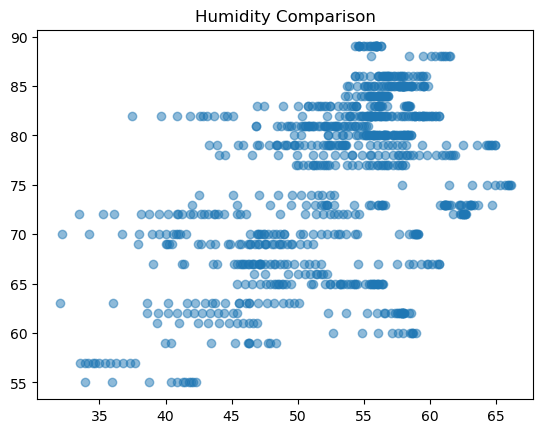

In [37]:
plt.scatter(scrubbed_data['Humidity (%) raw'], scrubbed_data['rh'], alpha=0.5)
plt.title('Humidity Comparison')
print('Max Humidity Difference: {:.2f}%'.format(np.max(np.abs(scrubbed_data['Humidity (%) raw'] - scrubbed_data['rh']))))

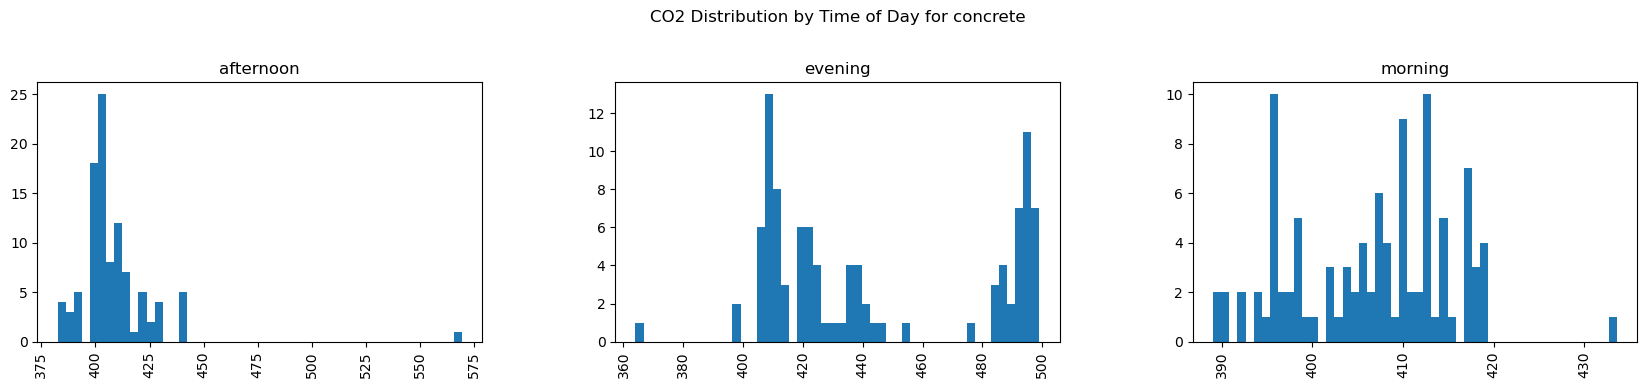

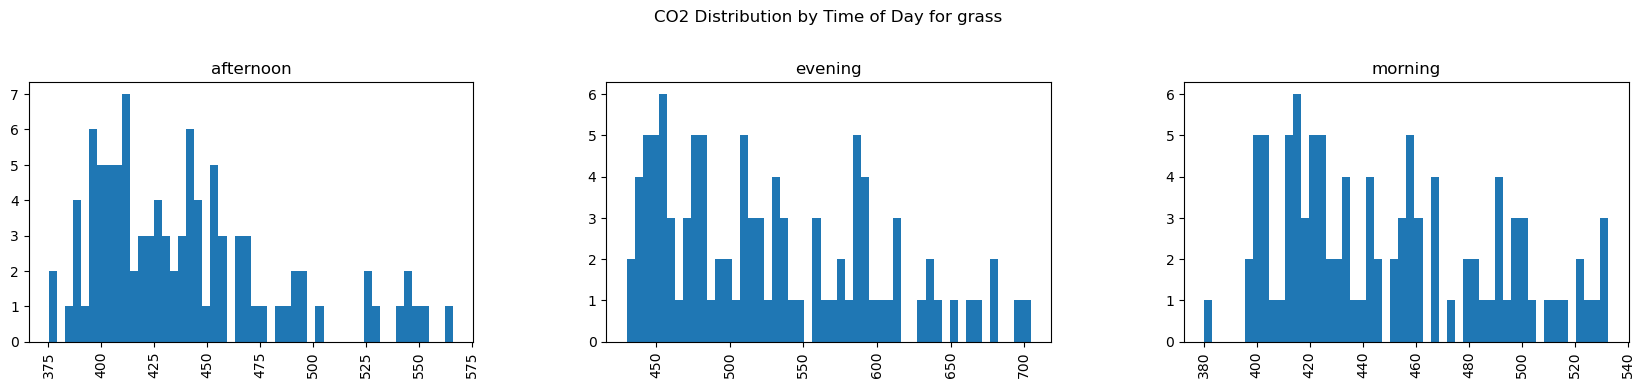

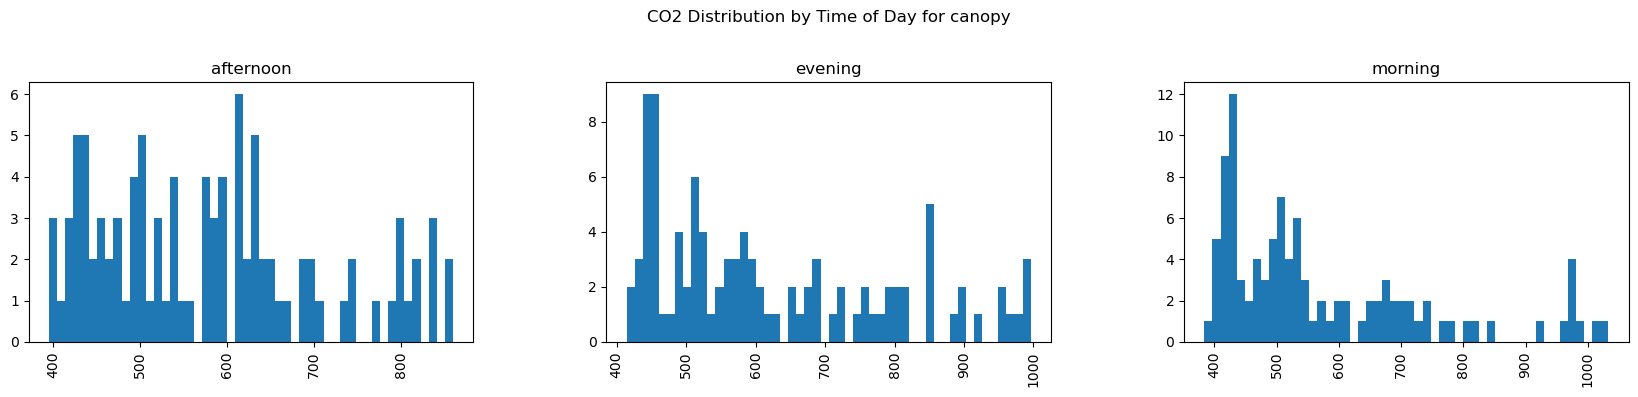

In [45]:
for ground in scrubbed_data['ground'].unique():
    ground_data = scrubbed_data.loc[scrubbed_data['ground'] == ground, ['co2_cal', 'tod']]
    ground_data.hist( by='tod', bins=50, label=ground, layout=(1,3), figsize = (20,4))
    plt.subplots_adjust(top = 0.8)
    plt.suptitle(f'CO2 Distribution by Time of Day for {ground}')
    

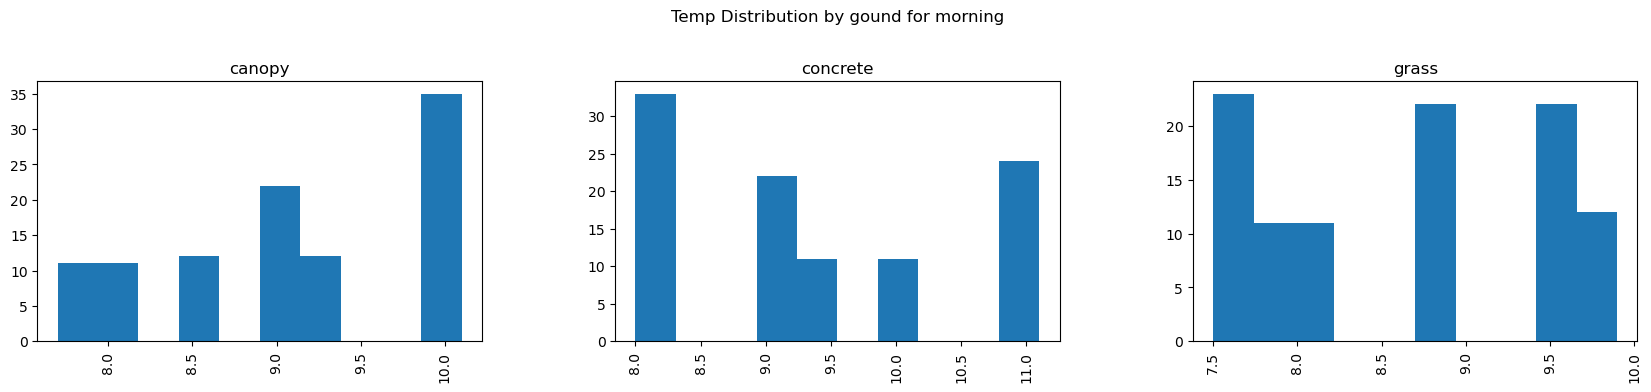

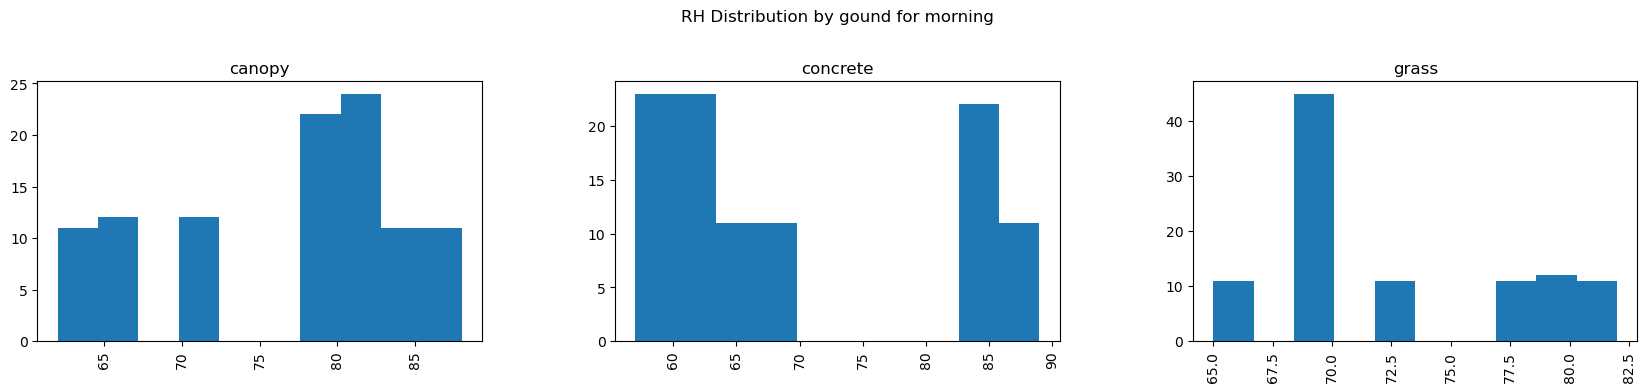

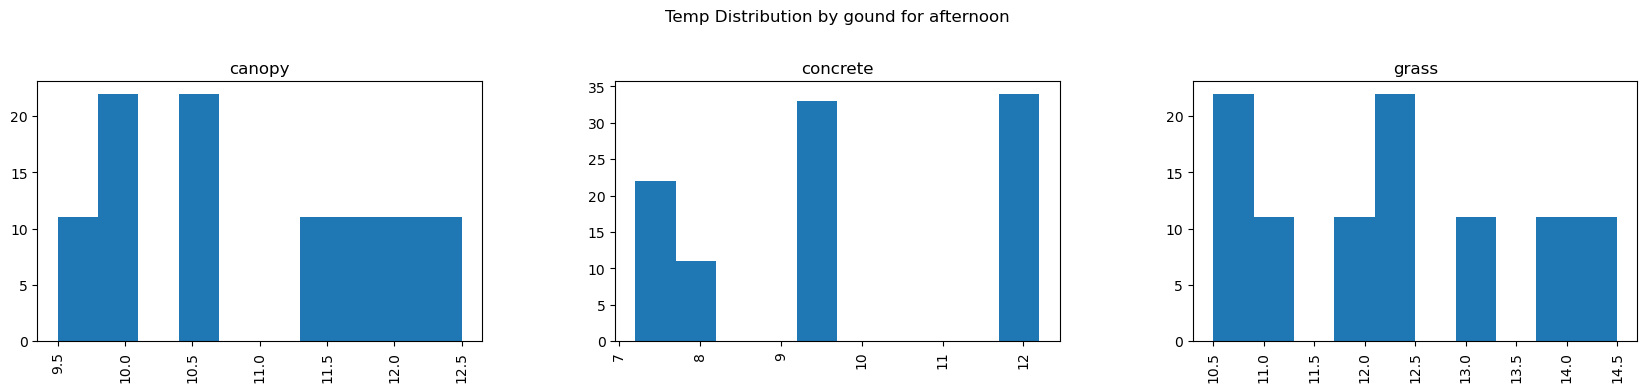

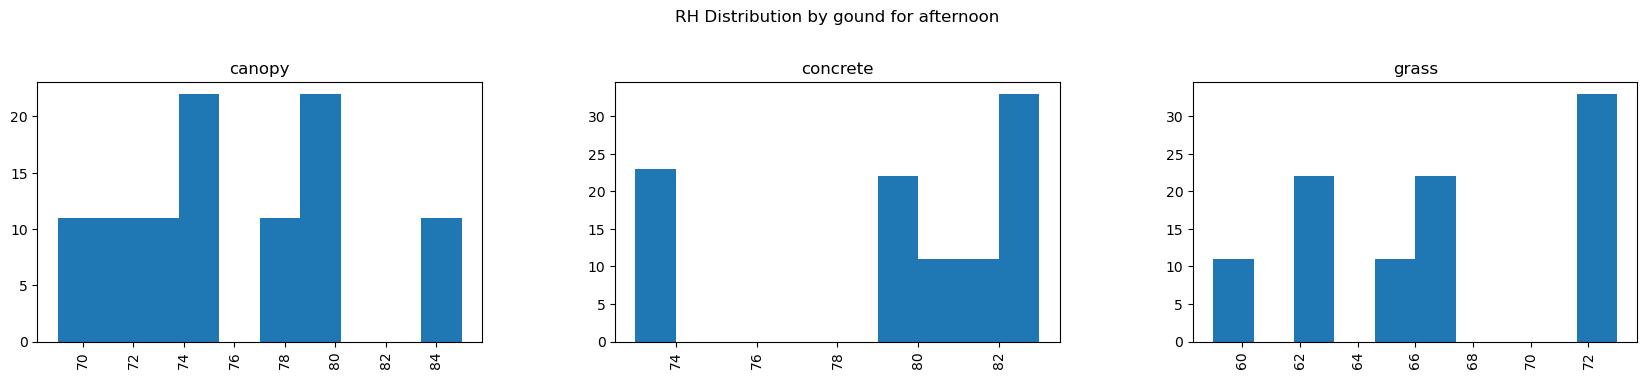

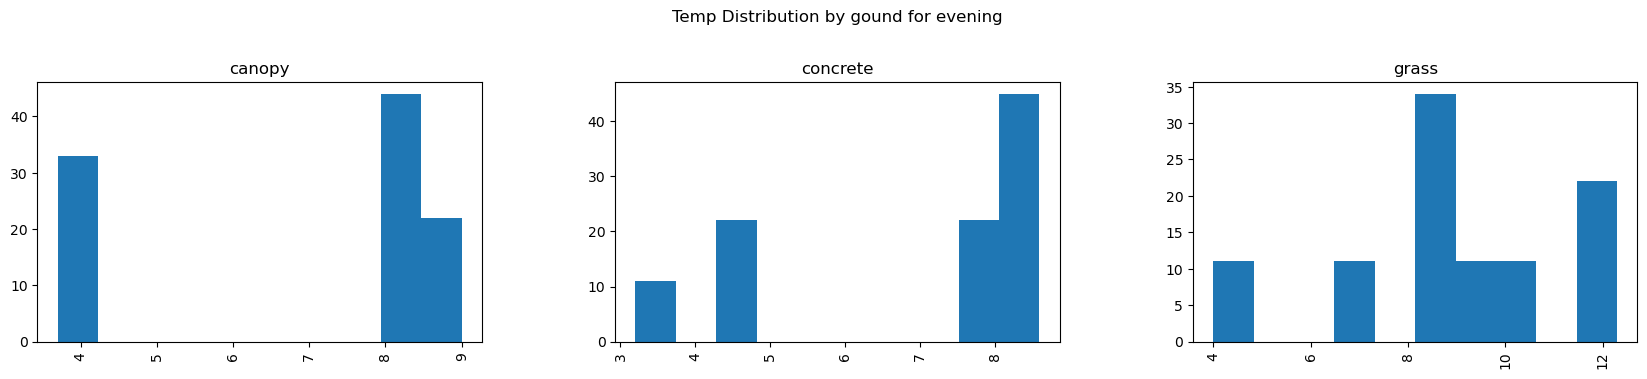

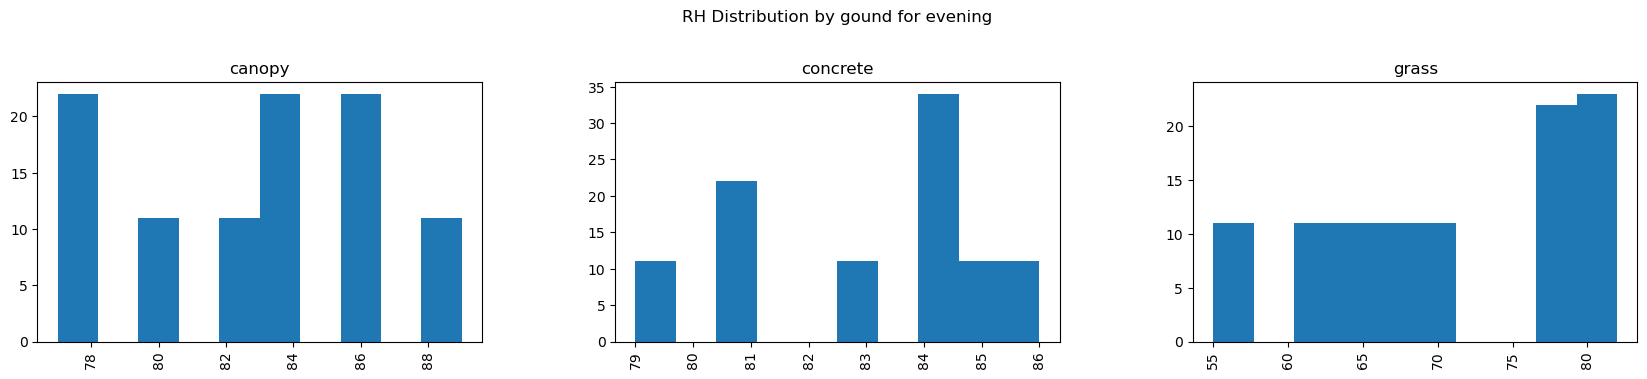

In [54]:
for tod in scrubbed_data['tod'].unique():
    tod_data = scrubbed_data.loc[scrubbed_data['tod'] == tod, ['temp', 'rh', 'ground']]
    tod_data.hist( 'temp', by='ground', bins=10, label=tod, layout=(1,3), figsize = (20,4))
    plt.subplots_adjust(top = 0.8)
    plt.suptitle(f'Temp Distribution by gound for {tod}')
    tod_data.hist( 'rh', by='ground', bins=10, label=tod, layout=(1,3), figsize = (20,4))
    plt.subplots_adjust(top = 0.8)
    plt.suptitle(f'RH Distribution by gound for {tod}')


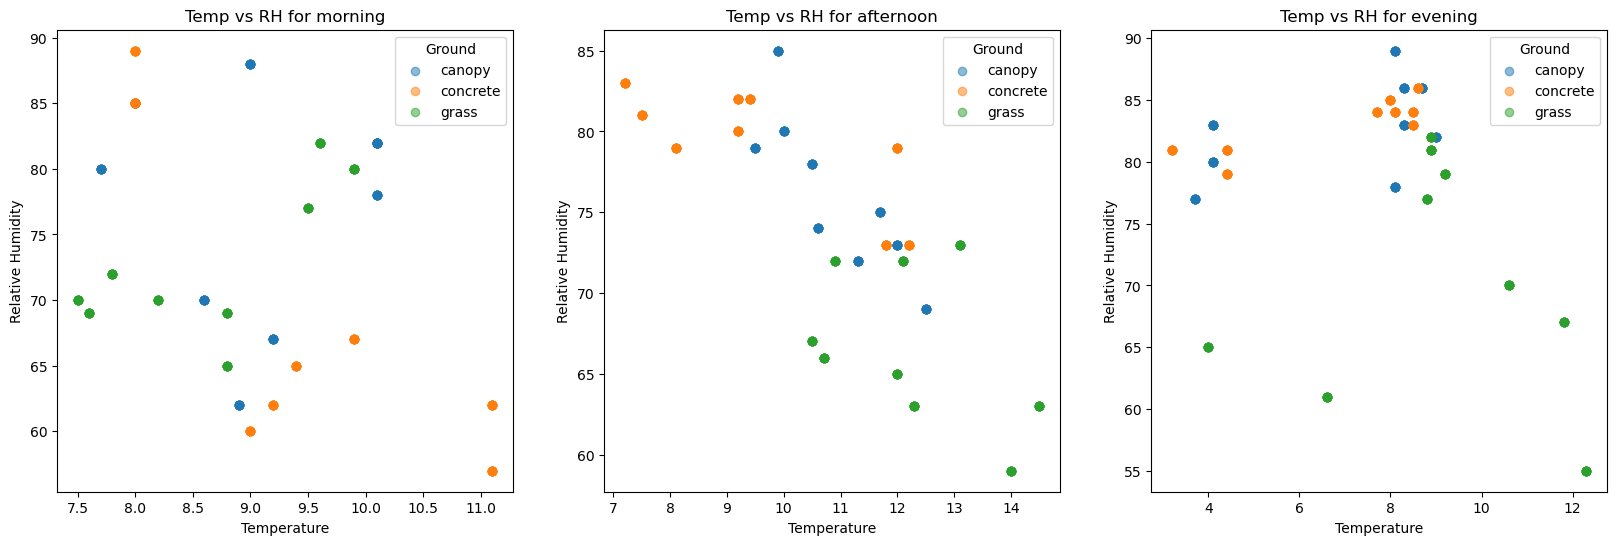

In [56]:
plt.figure(figsize=(20, 6))
for tod in scrubbed_data['tod'].unique():
    tod_data = scrubbed_data.loc[scrubbed_data['tod'] == tod, ['temp', 'rh', 'ground']]
    plt.subplot(1,3,scrubbed_data['tod'].unique().tolist().index(tod)+1)
    for ground, ground_data in tod_data.groupby('ground'):
        plt.scatter(
            ground_data['temp'],
            ground_data['rh'],
            alpha=0.5,
            label=ground
        )

    plt.xlabel('Temperature')
    plt.ylabel('Relative Humidity')
    plt.legend(title='Ground')
    plt.title(f'Temp vs RH for {tod}')

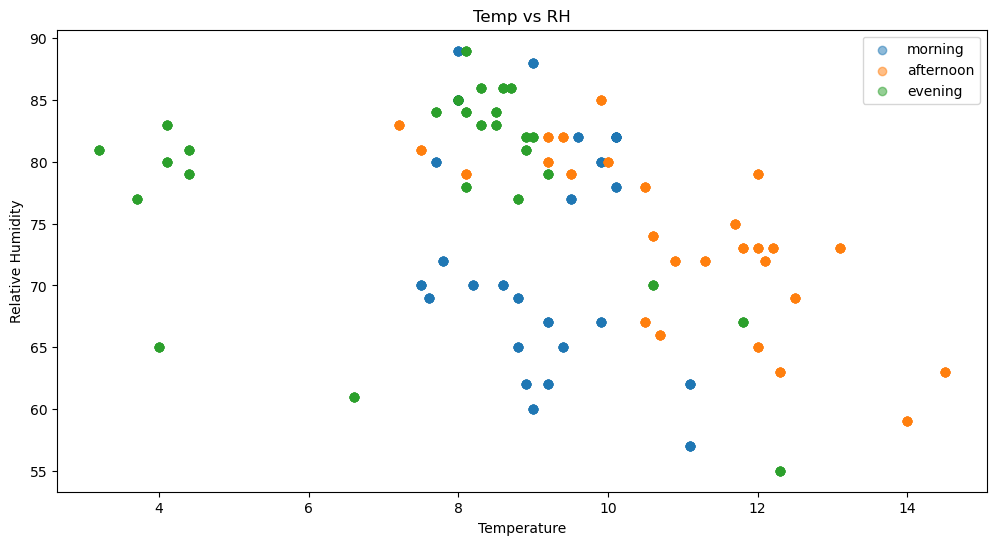

In [58]:
plt.figure(figsize=(12, 6))
for tod in scrubbed_data['tod'].unique():
    tod_data = scrubbed_data.loc[scrubbed_data['tod'] == tod, ['temp', 'rh', 'ground']]
    plt.scatter(
        tod_data['temp'],
        tod_data['rh'],
        alpha=0.5,
        label=tod
    )

    plt.xlabel('Temperature')
    plt.ylabel('Relative Humidity')
    plt.legend()
    plt.title(f'Temp vs RH')